# Campaign throughput and resource usage: Pro and Verified

Qwen3.5-9B · native AgentENV · two GH200 nodes / eight rollout GPUs.
Each campaign uses 128 fixed groups × 8 episodes at group limits 8/16/32/64.
Configured episode ceilings (64/128/256/512) appear on the x-axis.

Both datasets use the same bar layout, series colors, fonts, legends, and
**separate 9 × 3.75-inch figure per benchmark**.
SWE-bench Pro and SWE-bench Verified are displayed and exported independently.
Axes use the same ranges; peak anonymous memory
uses 0–250 GiB for both to include Verified's 212 GiB maximum.
Only Pro's 512-episode point is hatched for its workload engine failure.
Verified's optional 128-group / 1024-episode point was skipped.

The Verified 256 point uses successful repetition **3674787** (81.89 verified episodes/min),
replacing its original engine-failure observation. Other points retain their original runs.
The same repetition supplies throughput, CPU/GPU activity, and peak memory.


In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'uni_agent').is_dir() and (p / 'meta/plot').is_dir())
PLOT = REPO / 'meta/plot'
DATA = PLOT / 'data/sandbox_sweep_20261015.csv'
FIGURES = PLOT / 'figure'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_style('ticks')
sns.set_style({'font.family': ['Roboto', 'DejaVu Sans'], 'font.size': 12})
sns.set_context('paper', font_scale=2,
                rc={'lines.linewidth': 3, 'lines.markersize': 10})
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
PALETTE = {
    'blue_main': '#0F4D92', 'blue_secondary': '#3775BA',
    'green_1': '#DDF3DE', 'green_2': '#AADCA9', 'green_3': '#8BCF8B',
    'red_1': '#F6CFCB', 'red_2': '#E9A6A1', 'red_strong': '#B64342',
    'neutral': '#CFCECE', 'highlight': '#FFD700',
    'teal': '#42949E', 'violet': '#9A4D8E',
}

In [2]:
provenance = json.loads(DATA.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == provenance['sha256']
runs = pd.read_csv(DATA).sort_values('episode_ceiling').reset_index(drop=True)
assert runs.episode_ceiling.tolist() == [64, 128, 256, 512]
assert (runs.episode_ceiling == runs.active_groups * 8).all()
assert (runs.state == 'completed').all() and (runs.groups_terminal == 128).all()
assert (runs.completed_episodes == 1024).all() and (runs.wall_seconds > 0).all()
for count, rate in [
    ('completed_episodes', 'completed_episodes_per_minute'),
    ('verified_episodes', 'verified_episodes_per_minute'),
    ('usable_episodes', 'usable_episodes_per_minute'),
]:
    assert np.allclose(runs[rate], 60 * runs[count] / runs.wall_seconds)
assert (runs.verified_episodes + runs.incomplete_verifications == runs.completed_episodes).all()

memory_path = PLOT / 'data/sandbox_sweep_20261015_memory.csv'
memory_provenance = json.loads(memory_path.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(memory_path.read_bytes()).hexdigest() == memory_provenance['sha256']
memory = pd.read_csv(memory_path)
assert memory.episode_ceiling.is_unique
runs = runs.merge(memory, on='episode_ceiling', validate='one_to_one')
selected = runs.copy()
display(selected[[
    'episode_ceiling', 'completed_episodes_per_minute',
    'verified_episodes_per_minute', 'rollout_sm_active_pct_mean',
    'sandbox_cpu_busy_pct_mean', 'peak_anonymous_memory_gib',
]].round(2))

verified_path = PLOT / 'data/verified_sweep_20261016.json'
verified_provenance = json.loads(verified_path.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(verified_path.read_bytes()).hexdigest() == verified_provenance['sha256']
verified_all = pd.DataFrame(json.loads(verified_path.read_text()))
verified = verified_all[verified_all.state == 'completed'].copy()
verified_memory_path = PLOT / 'data/verified_sweep_20261016_memory.csv'
verified_memory_provenance = json.loads(verified_memory_path.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(verified_memory_path.read_bytes()).hexdigest() == verified_memory_provenance['sha256']
verified = verified.merge(pd.read_csv(verified_memory_path), on='episode_ceiling', validate='one_to_one')
verified = verified.sort_values('episode_ceiling').reset_index(drop=True)
CAMPAIGNS = [('SWE-bench Pro V2', selected), ('SWE-bench Verified', verified)]
for benchmark, frame in CAMPAIGNS:
    print(benchmark)
    display(frame[['episode_ceiling', 'completed_episodes_per_minute',
                   'verified_episodes_per_minute', 'rollout_sm_active_pct_mean',
                   'sandbox_cpu_busy_pct_mean', 'peak_anonymous_memory_gib']].round(2))

,episode_ceiling,completed_episodes_per_minute,verified_episodes_per_minute,rollout_sm_active_pct_mean,sandbox_cpu_busy_pct_mean,peak_anonymous_memory_gib
0,64,28.62,24.79,7.63,40.86,69.75
1,128,56.99,43.63,11.39,90.37,109.18
2,256,80.05,41.90,15.00,95.25,174.60
3,512,77.06,36.80,6.96,85.38,198.59


SWE-bench Pro V2


,episode_ceiling,completed_episodes_per_minute,verified_episodes_per_minute,rollout_sm_active_pct_mean,sandbox_cpu_busy_pct_mean,peak_anonymous_memory_gib
0,64,28.62,24.79,7.63,40.86,69.75
1,128,56.99,43.63,11.39,90.37,109.18
2,256,80.05,41.90,15.00,95.25,174.60
3,512,77.06,36.80,6.96,85.38,198.59


SWE-bench Verified


,episode_ceiling,completed_episodes_per_minute,verified_episodes_per_minute,rollout_sm_active_pct_mean,sandbox_cpu_busy_pct_mean,peak_anonymous_memory_gib
0,64,37.93,37.93,7.02,29.41,40.76
1,128,60.53,60.47,17.21,64.86,75.27
2,256,82.46,81.89,19.98,90.26,138.07
3,512,68.59,67.31,15.84,88.93,212.42


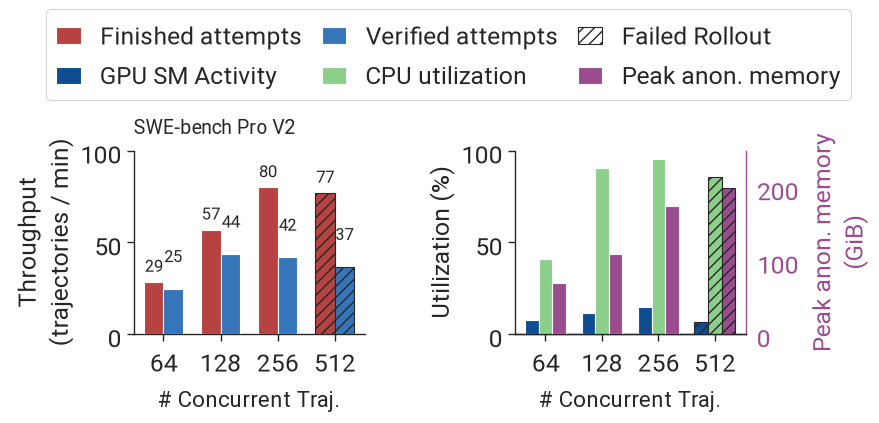

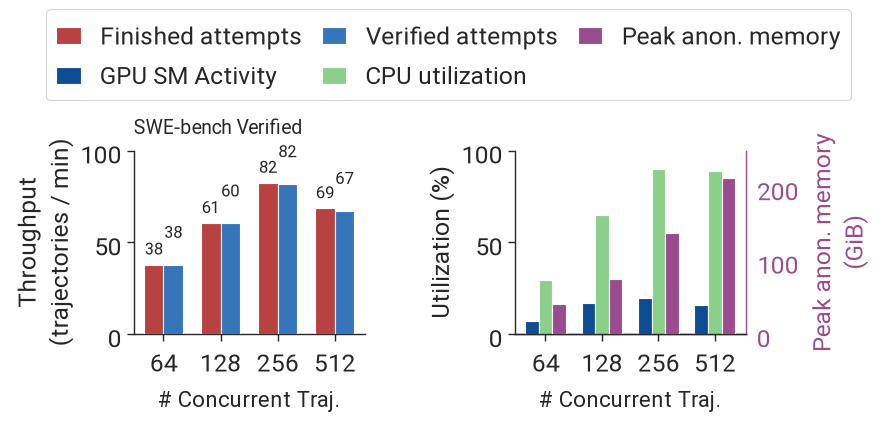

In [3]:
from matplotlib.patches import Patch

def draw_campaign(throughput_ax, gpu_ax, selected, benchmark):
    memory_ax = gpu_ax.twinx()
    x = np.arange(len(selected))
    width = .24
    for axis in (throughput_ax, gpu_ax):
        axis.set_xticks(x, selected.episode_ceiling.astype(str))
        axis.set_xlabel('# Concurrent Traj.', fontsize=16)

    throughput_bars = throughput_ax.bar(
        x - .17, selected.completed_episodes_per_minute, width=.34,
        color=PALETTE['red_strong'], label='Finished attempts', zorder=3)
    verified_bars = throughput_ax.bar(
        x + .17, selected.verified_episodes_per_minute, width=.34,
        color=PALETTE['blue_secondary'], label='Verified attempts', zorder=3)
    gpu_bars = gpu_ax.bar(
        x - width, selected.rollout_sm_active_pct_mean, width=width,
        color=PALETTE['blue_main'], label='GPU SM Activity', zorder=3)
    cpu_bars = gpu_ax.bar(
        x, selected.sandbox_cpu_busy_pct_mean, width=width,
        color=PALETTE['green_3'], label='CPU utilization', zorder=3)
    memory_bars = memory_ax.bar(
        x + width, selected.peak_anonymous_memory_gib, width=width,
        color=PALETTE['violet'], label='Peak anon. memory', zorder=3)

    # Hatch every metric at 512; preserve its measured height and series color.
    if benchmark == 'SWE-bench Pro V2':
        failed_index = selected.episode_ceiling.tolist().index(512)
        for bars in (throughput_bars, verified_bars, gpu_bars, cpu_bars, memory_bars):
            bars[failed_index].set_hatch('///')
            bars[failed_index].set_edgecolor('#272727')
            bars[failed_index].set_linewidth(.8)
    failed_handle = Patch(facecolor='white', edgecolor='#272727', hatch='///', label='Failed Rollout')
    throughput_ax.set_title(benchmark, loc='left', fontsize=14, pad=12)
    throughput_ax.set(ylabel='Throughput\n(trajectories / min)', ylim=(0, 100))
    gpu_ax.set(ylabel='Utilization (%)', ylim=(0, 100))
    memory_ax.set(ylabel='Peak anon. memory\n(GiB)', ylim=(0, 250))
    for axis in (throughput_ax, gpu_ax, memory_ax):
        axis.yaxis.label.set_fontsize(17.6)
    gpu_ax.yaxis.label.set_color('#272727')
    gpu_ax.tick_params(axis='y', colors='#272727')
    memory_ax.yaxis.label.set_color(PALETTE['violet'])
    memory_ax.tick_params(axis='y', colors=PALETTE['violet'])
    sns.despine(ax=throughput_ax)
    sns.despine(ax=gpu_ax)
    sns.despine(ax=memory_ax, left=True, right=False)
    memory_ax.spines['right'].set_color(PALETTE['violet'])
    gpu_ax.spines['left'].set_color('#272727')
    throughput_ax.bar_label(throughput_bars, fmt='%.0f', padding=4, fontsize=12)
    throughput_ax.bar_label(verified_bars, fmt='%.0f', padding=16, fontsize=12)
    return [throughput_bars, verified_bars, failed_handle, gpu_bars, cpu_bars, memory_bars]


def render_campaigns(campaigns, filename):
    if len(campaigns) != 1:
        raise ValueError('Render one benchmark per figure.')
    count = len(campaigns)
    fig, axes = plt.subplots(count, 2, figsize=(9, 3.75 * count), squeeze=False)
    fig.subplots_adjust(left=.15, right=.83, bottom=.23 / count,
                        top=.72 if count == 1 else .77, wspace=.65, hspace=.65)
    handles = None
    for (benchmark, frame), (throughput_ax, gpu_ax) in zip(campaigns, axes):
        row_handles = draw_campaign(throughput_ax, gpu_ax, frame, benchmark)
        if handles is None:
            handles = row_handles
    order = (0, 3, 1, 4, 2, 5) if any(name == 'SWE-bench Pro V2' for name, _ in campaigns) else (0, 3, 1, 4, 5)
    fig.legend(handles=[handles[i] for i in order], loc='upper center',
               bbox_to_anchor=(.5, 1.13 if count == 1 else 1.02), ncol=3,
               fontsize=17.6, columnspacing=.8, handlelength=1.0,
               labelspacing=.3, frameon=True)
    for extension in ('pdf', 'png', 'svg'):
        fig.savefig(FIGURES / f'{filename}.{extension}', dpi=300,
                    facecolor='white', bbox_inches='tight')
    display(fig)
    plt.close(fig)
for campaign, suffix in zip(CAMPAIGNS, ('pro', 'verified')):
    render_campaigns([campaign], f'concurrency_throughput_{suffix}')

Verified completed reward-verification throughput is **37.93, 60.47, 81.89,
and 67.31 episodes/min** at ceilings 64/128/256/512. It had 0/1/7/19 incomplete
verifications respectively. Missing stored usable trajectories are reported
separately in the frozen results and are not equivalent to verification failure.

The 256 point is a later successful repetition: 1,024 usable trajectories,
1,017 completed reward verifications, 7 incomplete verifications, and no engine failure.
The superseded observation (55.08 verified/min, 984 usable trajectories) remains in provenance.
These are individual measurements, without statistical error bars. Model
initialization is excluded; native sandbox setup remains included. CPU and GPU
counter percentages have different definitions. Peak anonymous memory is the
maximum `aenv.service` cgroup `memory.stat anon` within each rollout window,
excluding file cache. Memory provenance files record source hashes and windows.

Pro's 512 point had a workload engine failure, and all Pro jobs reported failure
in Ray teardown after results were written. Verified used the corrected verifier
command deadline, warmed images, and per-sandbox uv setup. This is not a controlled
cross-benchmark comparison: task workloads and provisioning costs differ.

Separate exports: `figure/concurrency_throughput_pro.{svg,pdf,png}` and
`figure/concurrency_throughput_verified.{svg,pdf,png}`.
All plotting inputs are frozen under `data/`; no remote access is needed.